In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
import os
import glob

# --- 1. Load Data ---
results_path = "test_results/strategy_one_repeats_results/"
csv_files = glob.glob(os.path.join(results_path, "results_*.csv"))

dfs = []
for f in csv_files:
    df = pd.read_csv(f)
    dfs.append(df)

if dfs:
    full_results_df = pd.concat(dfs, ignore_index=True)
    # Ensure the 'strategy' column exists since run_dce_logit filters by it
    if 'strategy' not in full_results_df.columns:
        full_results_df['strategy'] = 'strategy_one'
    
    print(f"Loaded {len(full_results_df)} records across {len(dfs)} models.")
else:
    print("No CSV files found.")

Loaded 1439 records across 4 models.


Prepared 1439 valid choice tasks.

OR + WTP (WITH CI)


,Model,OR_cost_diff,OR_cost_diff_CI_low,OR_cost_diff_CI_high,OR_inf_diff,OR_inf_diff_CI_low,OR_inf_diff_CI_high,WTP,WTP_CI_low,WTP_CI_high,N
0,deepseek/deepseek-chat-v3.1,1.884341,1.552678,2.286850,1.000000,NaN,NaN,0.000000,NaN,NaN,360
1,google/gemini-2.5-flash,1.645172,1.280608,2.113519,0.810454,0.777064,0.845280,-0.422140,-0.627544,-0.216736,359
2,openai/gpt-5-nano,0.224200,0.147151,0.341594,0.686068,0.632712,0.743924,0.251989,0.197609,0.306369,360
3,x-ai/grok-4-fast,0.166594,0.096402,0.287894,0.588542,0.517850,0.668883,0.295787,0.230118,0.361456,360


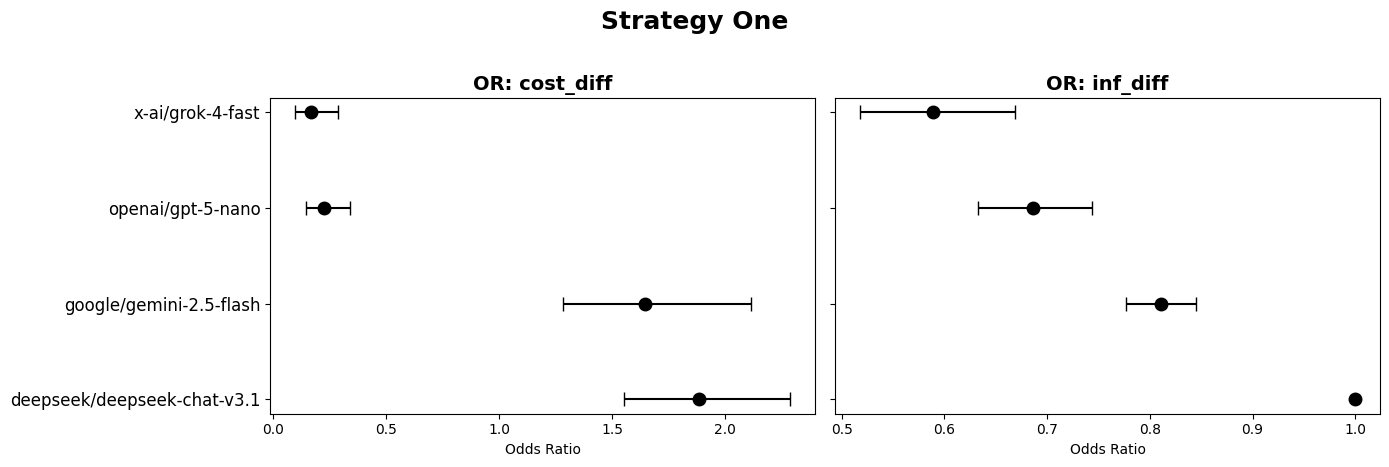

In [3]:

def run_dce_logit(
    results_df,
    strategy="strategy_one",
    detailed=False,
    min_obs=10,
    plot=True
):
    # --- 1. Filter strategy ---
    df = results_df[results_df["strategy"] == strategy].copy()

    # --- 2. Ensure numeric ---
    num_cols = [
        "infection_rate_selected",
        "infection_rate_non_selected",
        "npi_level_selected",
        "npi_level_non_selected",
    ]
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # --- 3. Binary choice (Option 1 chosen?) ---
    df["choice"] = (
        df["selected_choice"]
        == df["pair"].str.split("-").str[0]
    ).astype(int)

    # --- 4. Reconstruct option attributes ---
    df["inf_1"] = np.where(df["choice"] == 1,
                           df["infection_rate_selected"],
                           df["infection_rate_non_selected"])
    df["inf_2"] = np.where(df["choice"] == 1,
                           df["infection_rate_non_selected"],
                           df["infection_rate_selected"])

    df["npi_1"] = np.where(df["choice"] == 1,
                           df["npi_level_selected"],
                           df["npi_level_non_selected"])
    df["npi_2"] = np.where(df["choice"] == 1,
                           df["npi_level_non_selected"],
                           df["npi_level_selected"])

    # --- 5. Difference coding ---
    df["cost_diff"] = df["npi_1"] - df["npi_2"]
    df["inf_diff"]  = df["inf_1"] - df["inf_2"]

    print(f"Prepared {len(df)} valid choice tasks.")

    summary_rows = []

    # --- 6. Estimate per model ---
    for model_name in df["model"].unique():
        m_df = df[df["model"] == model_name].dropna(
            subset=["choice", "cost_diff", "inf_diff"]
        )

        if len(m_df) < min_obs:
            continue

        X = m_df[["cost_diff", "inf_diff"]]
        X = sm.add_constant(X)
        y = m_df["choice"]

        try:
            model = sm.Logit(y, X)
            res = model.fit_regularized(method='l1', alpha=0.01, disp=False)
            
            # ---- ORs + 95% CI using statsmodels conf_int ----
            params = res.params
            conf = res.conf_int()  # columns: [0]=low, [1]=high
            or_vals = np.exp(params)
            or_ci_low = np.exp(conf[0])
            or_ci_high = np.exp(conf[1])

            # --- WTP + delta-method CI ---
            wtp = np.nan
            wtp_low = np.nan
            wtp_high = np.nan

            b_cost = params.get("cost_diff", np.nan)
            b_inf = params.get("inf_diff", np.nan)

            if pd.notna(b_cost) and b_cost != 0 and pd.notna(b_inf):
                wtp = b_inf / b_cost
                cov = res.cov_params()
                if ("cost_diff" in cov.index) and ("inf_diff" in cov.index):
                    grad = np.array([
                        -b_inf / (b_cost ** 2),
                        1.0 / b_cost
                    ])
                    cov2 = cov.loc[["cost_diff", "inf_diff"], ["cost_diff", "inf_diff"]].to_numpy()
                    wtp_se = float(np.sqrt(grad @ cov2 @ grad))
                    wtp_low = wtp - 1.96 * wtp_se
                    wtp_high = wtp + 1.96 * wtp_se

            summary_rows.append({
                "Model": model_name,
                "OR_cost_diff": float(or_vals["cost_diff"]),
                "OR_cost_diff_CI_low": float(or_ci_low["cost_diff"]),
                "OR_cost_diff_CI_high": float(or_ci_high["cost_diff"]),
                "OR_inf_diff": float(or_vals["inf_diff"]),
                "OR_inf_diff_CI_low": float(or_ci_low["inf_diff"]),
                "OR_inf_diff_CI_high": float(or_ci_high["inf_diff"]),
                "WTP": float(wtp) if pd.notna(wtp) else np.nan,
                "WTP_CI_low": float(wtp_low) if pd.notna(wtp_low) else np.nan,
                "WTP_CI_high": float(wtp_high) if pd.notna(wtp_high) else np.nan,
                "N": int(len(m_df))
            })
            
        except Exception as e:
            print(f"Skipping model {model_name} due to error: {e}")
            continue

    summary_df = pd.DataFrame(summary_rows).sort_values("Model").reset_index(drop=True)

    print("\n" + "=" * 60)
    print("OR + WTP (WITH CI)")
    print("=" * 60)
    display(summary_df)

    # --- 7. Plot: Forest Plot (Box-and-whisker style) ---
    if plot and not summary_df.empty:
        plot_df = summary_df.copy()
        plot_df["Model"] = plot_df["Model"].astype(str)
        
        # We need two subplots: one for Cost Diff OR, one for Inf Diff OR
        fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 0.6 * len(plot_df) + 2), sharey=True)
        
        configs = [
            (axes[0], "OR_cost_diff", "OR_cost_diff_CI_low", "OR_cost_diff_CI_high", "OR: cost_diff"),
            (axes[1], "OR_inf_diff", "OR_inf_diff_CI_low", "OR_inf_diff_CI_high", "OR: inf_diff")
        ]

        y_positions = np.arange(len(plot_df))

        for ax, x_col, low_col, high_col, title in configs:
            
            for idx, row in plot_df.iterrows():
                mean_val = row[x_col]
                low_val = row[low_col]
                high_val = row[high_col]
                
                # Logic: Check if CI is valid and range <= 10
                ci_range = high_val - low_val
                is_valid_ci = (
                    pd.notna(low_val) and 
                    pd.notna(high_val) and 
                    ci_range <= 10
                )
                
                y_pos = idx 
                
                if is_valid_ci:
                    left_err = mean_val - low_val
                    right_err = high_val - mean_val
                    
                    # Plot with error bars (whiskers)
                    ax.errorbar(
                        x=mean_val, 
                        y=y_pos, 
                        xerr=[[left_err], [right_err]], 
                        fmt='o', 
                        markersize=9, 
                        color='black', 
                        capsize=5,
                        ecolor='black'
                    )
                else:
                    # Just plot the dot
                    ax.plot(mean_val, y_pos, 'o', markersize=9, color='black')

            # Formatting
            ax.set_yticks(y_positions)
            ax.set_yticklabels(plot_df["Model"], fontsize=12)
            ax.set_title(title, fontsize=14, fontweight='bold')
            ax.set_xlabel("Odds Ratio")
            
            # REMOVED: grid and vertical line at x=1
            # ax.grid(...) 
            # ax.axvline(...)

        # Add Main Title referencing Strategy
        clean_strategy = format_strategy_name(strategy)
        fig.suptitle(f"{clean_strategy}", fontsize=18, fontweight='bold', y=1.05)

        plt.tight_layout()
        plt.subplots_adjust(top=0.85) # Adjust top to make room for the new title
        plt.show()

    return summary_df

# --- 2. Run Analysis ---
if 'full_results_df' in locals():
    # Simple helper if not defined
    if 'format_strategy_name' not in globals():
        def format_strategy_name(s):
            return s.replace("_", " ").title()
            
    analysis_results = run_dce_logit(full_results_df, strategy="strategy_one")
